# Industrial Visual Anomaly Detection

### Problem Statement
Industrial visual anomaly detection aims to distinguish defective products from normal products using images from production. A model can perform two related tasks:

- **Anomaly detection:** determines whether an entire image contains a defect.
- **Anomaly localization:** identifies the pixels or regions where the defect is located.

In industrial settings, normal products are common while defective products are rare. Collecting representative examples of every possible defect is therefore difficult. Unsupervised or one-class anomaly detection methods solve this problem by learning only from normal images. During testing, an image is considered anomalous when its visual representation differs from the learned representation of normal samples.

```text
Normal training images
        │
        ▼
Learn the appearance of normal products
        │
        ▼
Compare a new image with the learned normal
        │
        ├── Small difference → normal
        │
        └── Large difference → anomaly
```

The AutoVI dataset includes images collected on real automotive assembly lines. As such, Lighting, positioning, vibration, background objects, and product variants may change even when no defect is present, which makes the assigned task a difficult one.

### Convolutional Neural Networks
A Convolutional Neural Network, or CNN, is a neural network that processes data with a spatial structure. Instead of examining every pixel independently, a CNN applies small learnable filters to local image regions. During training, the network learns which filters are useful for the task.

For each position in an image, a convolutional filter calculates a weighted combination of nearby pixel values. The same filter is applied across the whole image.

The result of the convolution is then passed through a nonlinear activation function. Nonlinear activations allow the network to learn relationships that cannot be represented through a sequence of linear transformations alone. Most common is the Rectified Linear Unit (ReLU), which  preserves positive responses and replaces negative responses with zero. 

CNN features are learned hierarchically:
- **Early layers:** edges, gradients, colours, and textures.
- **Intermediate layers:** shapes, repeated structures, and object parts.
- **Deeper layers:** components and higher-level spatial patterns.

This hierarchy makes CNNs useful for both classification and anomaly detection. A supervised CNN can directly classify images, while methods such as PaDiM use intermediate CNN features to model normal image regions.

The CNN architecture works as follows:


```text
Input image
    │
    ▼
Convolutional filters
    │
    ├── edges
    ├── corners
    ├── textures
    └── colour transitions
    │
    ▼
Deeper convolutional layers
    │
    ├── shapes
    ├── components
    └── spatial arrangements
    │
    ▼
Feature representation
    │
    ▼
Prediction
```





### ResNet18 (Residual learning)
ResNet18 is an 18-layer convolutional neural network based on residual learning. In a conventional deep network, every group of layers must learn a complete transformation from its input to its output. A residual block instead learns only the change that should be applied to the input.

For an input $x$, a residual block produces:

$$
y = F(x) + x
$$

where:
- $x$ is the original input,
- $F(x)$ is the transformation learned by the convolutional layers,
- $y$ is the block output.

The direct path from $x$ to $y$ is called a skip connection. Skip connections provide a shorter path for information and gradients. If a residual block does not need to modify its input substantially, the block can learn a residual close to zero and preserve the original representation.

The ResNet18 architecture works as follows:

```text
Image
  │
  ▼
Initial convolution
  │
  ▼
Residual stage 1
  │
  ▼
Residual stage 2
  │
  ▼
Residual stage 3
  │
  ▼
Residual stage 4
  │
  ▼
Global average pooling
  │
  ▼
Classification layer
```





### PaDiM

PaDiM (Patch Distribution Modeling) is an unsupervised, one-class method for image-level anomaly detection and pixel-level anomaly localization.

PaDiM is trained only with normal images. It does not learn a direct boundary between known normal and defective examples. Instead, it builds a statistical model of the features normally expected at each spatial position.

PaDiM includes multiple stages, namely feature extraction, dimensionality reduction, modelling of normal patches, anomaly scoring and anomaly map generation.

The PaDiM architecture works as follows:


```text
Normal images
     │
     ▼
Pretrained CNN
     │
     ▼
Patch embeddings from several CNN layers
     │
     ▼
Gaussian distribution for each spatial position
     │
     ▼
Statistical model of normal appearance
```

### FedAvg

FedAvg (Federated Averaging) is a standard algorithm for combining locally trained models. It is based on federated learning, which trains a shared model using data stored by several clients without transferring the raw data to a central dataset. The server coordinates training, but each client processes its own data locally.

Each communication round contains four main steps, namely:
- Model distribution: The server sends the current global model parameters to the selected client;
- Local training: Each client initializes its local model with the global parameters and trains the model using only its own data;
- Parameter transmission: The clients return model parameters or parameter updates to the server;
- Weighted aggregation: The server calculates a sample-weighted average, and a client containing more training samples receives a larger aggregation weight. 

The FedAvg architecture works as follows:

```text
                    Global model
                         │
          ┌──────────────┼──────────────┐
          ▼              ▼              ▼
       Client 1       Client 2       Client 3
       Local data     Local data     Local data
          │              │              │
          ▼              ▼              ▼
     Local training  Local training  Local training
          │              │              │
          └──────────────┼──────────────┘
                         ▼
                Aggregate parameters
                         │
                         ▼
                 New global model
```


### Performance Metrics

#### Confusion matrix
The truth table is as follows:

| Ground truth | Predicted anomaly | Predicted normal |
|---|---:|---:|
| Anomaly | True Positive (TP) | False Negative (FN) |
| Normal | False Positive (FP) | True Negative (TN) |

where:
- **True Positive:** a defect is correctly detected.
- **True Negative:** a normal product is correctly accepted.
- **False Positive:** a normal product is incorrectly flagged as defective.
- **False Negative:** a defective product is incorrectly accepted as normal.


#### Accuracy
Accuracy is the proportion of all correct predictions:

$$
\text{Accuracy}
=
\frac{TP+TN}{TP+TN+FP+FN}.
$$


#### True Positive Rate
The True Positive Rate (recall or sensitivity) measures the proportion of anomalies that are detected:

$$
TPR = \frac{TP}{TP+FN}.
$$


#### False Negative Rate
The False Negative Rate measures the proportion of anomalies that are missed:

$$
FNR = \frac{FN}{TP+FN}.
$$


#### True Negative Rate
The True Negative Rate (specificity) measures the proportion of normal products correctly accepted:

$$
TNR = \frac{TN}{TN+FP}.
$$


#### False Positive Rate
The False Positive Rate measures the proportion of normal products incorrectly classified as defective:

$$
FPR = \frac{FP}{FP+TN}.
$$


#### Precision

Precision measures how many images predicted as anomalous are actually anomalous:

$$
\text{Precision} = \frac{TP}{TP+FP}.
$$



#### F1-score
The F1-score is the harmonic mean of precision and recall:

$$
F1
=
2\cdot
\frac{\text{Precision}\cdot\text{Recall}}
{\text{Precision}+\text{Recall}}.
$$


#### AUROC
The Area Under the Receiver Operating Characteristic Curve summarizes the ROC curve into one value. The ROC curve (Receiver Operating Characteristic curve) plots TPR against FPR for every possible decision threshold. A curve close to the upper-left corner indicates good separation between normal and anomalous scores. The diagonal corresponds to random ranking.

A score of $1.0$ is considered perfect score separation.


#### AP

AP (Average Precision) summarizes the precision-recall curve:

$$
AP = \sum_n (R_n-R_{n-1})P_n,
$$

where $P_n$ and $R_n$ are precision and recall at threshold $n$.

The precision-recall curve plots precision against recall for different thresholds. The curve shows whether the model can detect more anomalies without producing too many false positives.

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from scipy.ndimage import gaussian_filter
from sklearn.metrics import (average_precision_score, balanced_accuracy_score,
                             f1_score, roc_auc_score, roc_curve)
from torchvision.models import ResNet18_Weights, resnet18

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_splitting").is_dir())
PARTS = REPO / "data" / "partitions" / "autovi"
RUNS = REPO / "outputs" / "experiments" / "padim-central"
FIGS = REPO / "outputs" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

SEEDS = [1, 2, 3]
N_DIMS = 100 # feature channels kept, out of 448
BATCH = 32
TNR = 0.95 # threshold / quantile of the normal validation scores
SIGMA = 4 # smoothing factor of the anomaly map 4 a 224 px image

dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")

### Data

- The partitions are resulted from `data_splitting/split_data.py`;
- One client per production part;
- Labels: 0 = normal, 1 = anomaly;
- Training uses the normal images only.

In [ ]:
def read(path, split):
    d = np.load(path)
    return d[f"x_{split}"], d[f"y_{split}"].reshape(-1)


files = sorted(PARTS.glob("client_*.npz"), key=lambda p: int(p.stem.split("_")[1]))
assert files, f"no partitions, please run data_splitting/split_data.py first"

train = [read(f, "train") for f in files]
val = [read(f, "val") for f in files]
x_test, y_test = read(PARTS / "test.npz", "test")

counts = pd.DataFrame(
    [[(ytr == 0).sum(), (ytr == 1).sum(), (yva == 0).sum(), (yva == 1).sum()]
     for (_, ytr), (_, yva) in zip(train, val)],
    columns=["train normal", "train anomaly (unused)", "val normal", "val anomaly"])
counts.index.name = "client"

print("images: ", x_test.shape[1:])
print(f"test: {(y_test == 0).sum()} normal, {(y_test == 1).sum()} anomalies")
counts

images: (64, 64, 3) uint8
test  : 600 normal, 189 anomaly


,train normal,train anomaly (unused),val normal,val anomaly
client,,,,
0,889,0,157,0
1,69,140,13,24
2,11,177,2,31
3,996,152,172,30
4,64,103,11,19


In [ ]:
x_pool = np.concatenate([x[y == 0] for x, y in train])
x_val = np.concatenate([x for x, _ in val])
y_val = np.concatenate([y for _, y in val])
owner = np.concatenate([np.full(len(y), c) for c, (_, y) in enumerate(val)])

print("pooled normal training images:", len(x_pool))
print("pooled validation images:", len(x_val))

pooled normal training images: 2029
pooled validation images     : 459


### Model Achitecture

In [4]:
MEAN = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)


class Backbone(torch.nn.Module):
    def __init__(self):
        super().__init__()
        r = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
        self.stem = torch.nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool)
        self.l1, self.l2, self.l3 = r.layer1, r.layer2, r.layer3

    def forward(self, x):
        f1 = self.l1(self.stem(x))
        f2 = self.l2(f1)
        f3 = self.l3(f2)
        hw = f1.shape[-2:]
        f2 = F.interpolate(f2, size=hw, mode="nearest")
        f3 = F.interpolate(f3, size=hw, mode="nearest")
        return torch.cat([f1, f2, f3], dim=1)


net = Backbone().to(dev).eval()


def batches(x):
    for i in range(0, len(x), BATCH):
        b = torch.from_numpy(x[i:i + BATCH]).to(dev)
        b = b.permute(0, 3, 1, 2).float() / 255
        yield (b - MEAN) / STD

In [5]:
class Padim:
    def __init__(self, seed):
        g = torch.Generator().manual_seed(seed)
        self.idx = torch.randperm(448, generator=g)[:N_DIMS].to(dev)
        self.n = 0

    @torch.no_grad()
    def embed(self, xb):
        f = net(xb)[:, self.idx]
        self.hw = tuple(f.shape[-2:])
        return f.flatten(2).transpose(1, 2)     # (batch, positions, dims)

    def add(self, x):
        for xb in batches(x):
            e = self.embed(xb).double().transpose(0, 1)     # (positions, batch, dims)
            if self.n == 0:
                p, _, d = e.shape
                self.s1 = e.new_zeros(p, d)         # sum of x
                self.s2 = e.new_zeros(p, d, d)      # sum of outer products
            self.s1 += e.sum(1)
            self.s2.baddbmm_(e.transpose(1, 2), e)
            self.n += e.shape[1]
        return self

    def finish(self):
        mu = self.s1 / self.n
        cov = self.s2 / (self.n - 1)
        cov -= self.n / (self.n - 1) * mu[:, :, None] * mu[:, None, :]
        cov += 0.01 * torch.eye(cov.shape[-1], dtype=cov.dtype, device=cov.device)
        self.mu = mu.float()
        # inverted in chunks, all positions at once takes too much memory on large images
        self.icov = torch.cat([torch.linalg.inv(c).float() for c in cov.split(1024)])
        return self

    @torch.no_grad()
    def maps(self, x):
        out = []
        for xb in batches(x):
            d = self.embed(xb) - self.mu
            m = torch.einsum("bpi,pij,bpj->bp", d, self.icov, d).clamp(min=0).sqrt()
            m = F.interpolate(m.view(-1, 1, *self.hw), size=xb.shape[-2:],
                              mode="bilinear", align_corners=False)
            out.append(m[:, 0].cpu().numpy())
        out = np.concatenate(out)
        s = SIGMA * out.shape[-1] / 224
        return gaussian_filter(out, sigma=(0, s, s))

    def score(self, x):
        return self.maps(x).reshape(len(x), -1).max(1)

### Evaluation

In [6]:
def evaluate(y, s, thr):
    pred = (s > thr).astype(int)
    both = len(np.unique(y)) == 2
    return {
        "accuracy": float((pred == y).mean()),
        "balanced_accuracy": float(balanced_accuracy_score(y, pred)),
        "f1_macro": float(f1_score(y, pred, average="macro", zero_division=0)),
        "auroc": float(roc_auc_score(y, s)) if both else float("nan"),
        "ap": float(average_precision_score(y, s)) if both else float("nan"),
        "tpr": float(pred[y == 1].mean()) if both else float("nan"),
        "tnr": float(1 - pred[y == 0].mean()),
    }

### Centralised and local runs
- Centralised: one model fitted on the normal training images of all clients together;
- Local: one model per client, fitted on the client's normal images only and evaluated on its own
validation set.

In [7]:
results, local = {}, {}

for seed in SEEDS:
    central = Padim(seed).add(x_pool).finish()
    s_val, s_test = central.score(x_val), central.score(x_test)
    thr = float(np.quantile(s_val[y_val == 0], TNR))

    res = {"val": evaluate(y_val, s_val, thr), "val_per_client": {},
           "test": evaluate(y_test, s_test, thr), "threshold": thr}
    for c in range(len(files)):
        m = owner == c
        res["val_per_client"][str(c)] = {"samples": int(m.sum()),
                                         **evaluate(y_val[m], s_val[m], thr)}

    loc = {}
    for c, ((xtr, ytr), (xva, yva)) in enumerate(zip(train, val)):
        s = Padim(seed).add(xtr[ytr == 0]).finish().score(xva)
        loc[str(c)] = evaluate(yva, s, float(np.quantile(s[yva == 0], TNR)))

    out = RUNS / f"seed{seed}"
    out.mkdir(parents=True, exist_ok=True)
    torch.save({"idx": central.idx.cpu(), "mean": central.mu.cpu(), "icov": central.icov.cpu(),
                "n": central.n, "hw": central.hw}, out / "final_model.pt")
    cfg = {"partitions-dir": str(PARTS), "seed": seed, "mode": "centralised",
           "model": "padim-resnet18", "n-dims": N_DIMS, "tnr": TNR}
    (out / "metrics.json").write_text(json.dumps({"run_config": cfg}, indent=2))
    (out / "results.json").write_text(json.dumps(res, indent=2))
    (out / "local.json").write_text(json.dumps(loc, indent=2))

    results[seed], local[seed] = res, loc
    print(f"seed {seed}: val auroc {res['val']['auroc']:.3f}, "
          f"val balanced acc {res['val']['balanced_accuracy']:.3f}")

/home/bia/Industrial-Anomaly-Detection/.venv_aitdm/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/bia/Industrial-Anomaly-Detection/.venv_aitdm/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


seed 1: val auroc 0.785, val balanced acc 0.604


/home/bia/Industrial-Anomaly-Detection/.venv_aitdm/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/bia/Industrial-Anomaly-Detection/.venv_aitdm/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


seed 2: val auroc 0.775, val balanced acc 0.561


/home/bia/Industrial-Anomaly-Detection/.venv_aitdm/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/bia/Industrial-Anomaly-Detection/.venv_aitdm/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


seed 3: val auroc 0.765, val balanced acc 0.571


### Results

In [8]:
def mean_std(v):
    v = np.array(v, dtype=float)
    return f"{v.mean():.3f} ± {v.std(ddof=1) if len(v) > 1 else 0:.3f}"


keys = ["auroc", "ap", "balanced_accuracy", "f1_macro", "accuracy", "tpr", "tnr"]
summary = pd.DataFrame(
    {split: [mean_std([results[s][split][k] for s in SEEDS]) for k in keys]
     for split in ("val", "test")}, index=keys)
summary

,val,test
auroc,0.775 ± 0.010,0.755 ± 0.009
ap,0.485 ± 0.048,0.481 ± 0.013
balanced_accuracy,0.579 ± 0.023,0.587 ± 0.014
f1_macro,0.585 ± 0.030,0.594 ± 0.019
accuracy,0.781 ± 0.010,0.768 ± 0.003
tpr,0.208 ± 0.045,0.238 ± 0.037
tnr,0.949 ± 0.000,0.936 ± 0.010


### Per client validation

In [9]:
rows = []
for c in map(str, range(len(files))):
    row = {"client": c, "val images": results[SEEDS[0]]["val_per_client"][c]["samples"]}
    for k, name in (("auroc", "auroc"), ("ap", "ap"), ("balanced_accuracy", "bal. acc.")):
        row[f"central {name}"] = mean_std([results[s]["val_per_client"][c][k] for s in SEEDS])
        row[f"local {name}"] = mean_std([local[s][c][k] for s in SEEDS])
    rows.append(row)
per_client = pd.DataFrame(rows).set_index("client")
per_client

,val images,central auroc,local auroc,central ap,local ap,central bal. acc.,local bal. acc.
client,,,,,,,
0,157,nan ± nan,nan ± nan,nan ± nan,nan ± nan,0.964 ± 0.007,0.949 ± 0.000
1,37,0.793 ± 0.040,0.749 ± 0.077,0.872 ± 0.041,0.865 ± 0.046,0.620 ± 0.022,0.677 ± 0.024
2,33,0.409 ± 0.186,0.134 ± 0.049,0.922 ± 0.040,0.886 ± 0.025,0.398 ± 0.200,0.293 ± 0.037
3,202,0.797 ± 0.011,0.797 ± 0.010,0.406 ± 0.074,0.387 ± 0.067,0.587 ± 0.030,0.563 ± 0.038
4,30,0.726 ± 0.007,0.600 ± 0.025,0.797 ± 0.045,0.718 ± 0.048,0.566 ± 0.029,0.516 ± 0.066


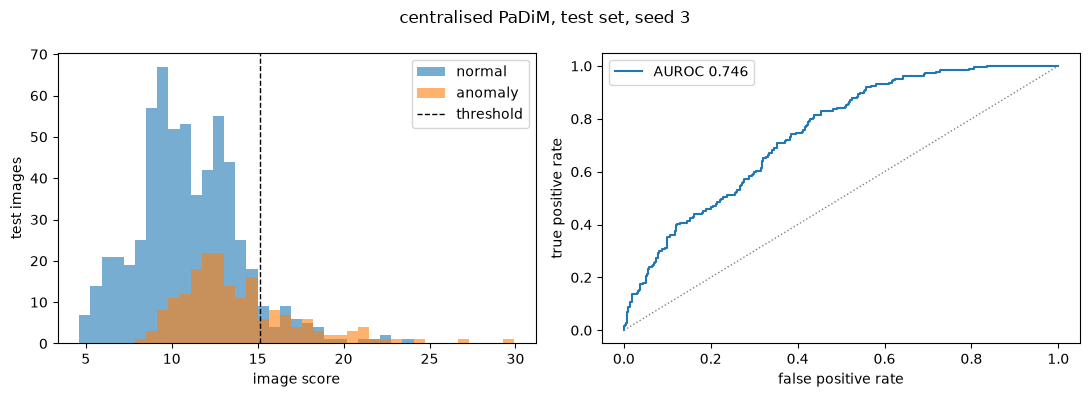

In [ ]:
# figures
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
bins = np.linspace(s_test.min(), s_test.max(), 40)
ax[0].hist(s_test[y_test == 0], bins=bins, alpha=0.6, label="normal")
ax[0].hist(s_test[y_test == 1], bins=bins, alpha=0.6, label="anomaly")
ax[0].axvline(thr, color="k", ls="--", lw=1, label="threshold")
ax[0].set_xlabel("image score")
ax[0].set_ylabel("test images")
ax[0].legend()

fpr, tpr, _ = roc_curve(y_test, s_test)
ax[1].plot(fpr, tpr, label=f"AUROC {roc_auc_score(y_test, s_test):.3f}")
ax[1].plot([0, 1], [0, 1], color="grey", ls=":", lw=1)
ax[1].set_xlabel("false positive rate")
ax[1].set_ylabel("true positive rate")
ax[1].legend()

fig.suptitle(f"centralised PaDiM, test set, seed {seed}")
fig.tight_layout()
fig.savefig(FIGS / "baseline_scores.png", dpi=150)

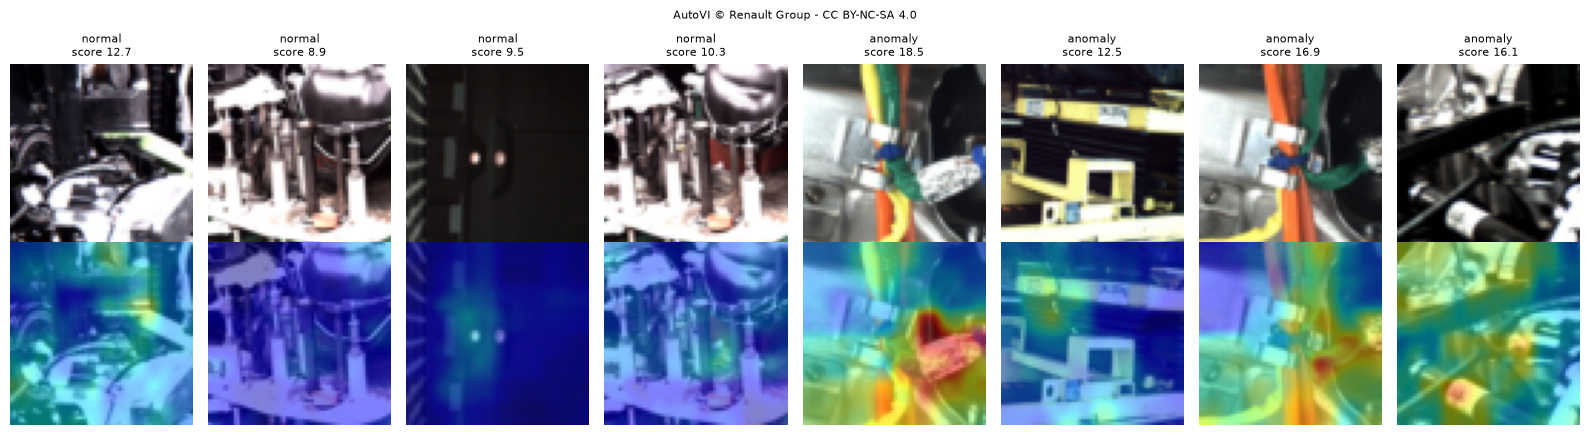

In [11]:
rng = np.random.default_rng(0)
pick = np.concatenate([rng.choice(np.where(y_test == k)[0], 4, replace=False) for k in (0, 1)])
amaps = central.maps(x_test[pick])

fig, ax = plt.subplots(2, len(pick), figsize=(2 * len(pick), 4.4))
for j, i in enumerate(pick):
    ax[0, j].imshow(x_test[i])
    ax[0, j].set_title(f"{'anomaly' if y_test[i] else 'normal'}\nscore {s_test[i]:.1f}", fontsize=8)
    ax[1, j].imshow(x_test[i])
    ax[1, j].imshow(amaps[j], cmap="jet", alpha=0.5, vmin=amaps.min(), vmax=amaps.max())
for a in ax.ravel():
    a.axis("off")
fig.suptitle("AutoVI © Renault Group - CC BY-NC-SA 4.0", fontsize=8)
fig.tight_layout()
fig.savefig(FIGS / "baseline_maps.png", dpi=150)

In [ ]:
# sum of client statistics

# n, s1, s2 = 0, 0, 0
# for x, y in train:
#     m = Padim(seed).add(x[y == 0])
#     n += m.n
#     s1 += m.s1
#     s2 += m.s2
#     del m

# print("images     :", n, "vs", central.n)
# print("sum x      :", float((s1 - central.s1).abs().max() / central.s1.abs().max()))
# print("sum x x^T  :", float((s2 - central.s2).abs().max() / central.s2.abs().max()))

images     : 2029 vs 2029
sum x      : 0.0
sum x x^T  : 4.912974071873135e-16
